# Логістична регресія: тяжкість ДТП (`Severity`)

Дані — результат `classification_data_preparation.ipynb` (`data/processed/classification/`): ознаки вже очищені, закодовані й масштабовані, ціль `label` (0…3 = Severity 1…4). Класи сильно незбалансовані (~78% — Severity 2).

**Модель — `pyspark.ml.classification.LogisticRegression`** (мультиноміальна, L-BFGS): лінійна модель, швидка й інтерпретована; навчання розподілене — Spark рахує градієнт порціями по всіх розділах даних, тож train не потрібно тримати в пам'яті драйвера.

**Етапи:**
1. Завантаження (`spark.read.parquet` → `VectorAssembler`) та експрес-перевірка даних.
2. Підбір гіперпараметра `regParam` на стратифікованій підвибірці train (`CrossValidator`, 5 стратифікованих фолдів, F1 macro).
3. Навчання на повному train: базові vs підібрані параметри × без зважування vs збалансовані ваги класів (`weightCol`) — 4 варіанти; таблиця метрик на train.
4. Valid: метрики всіх варіантів → лідер за F1 macro → підбір порогів рішення → матриці помилок і ROC-криві train vs valid.
5. Test: фінальна оцінка лідера.
6. SHAP: beeswarm і bar chart важливості ознак.

**Усі обчислення — у Spark:** навчання, прогнози, матриці помилок, метрики, ROC-криві, підбір порогів. На драйвер потрапляють лише малі підсумки (матриця помилок 4 × 4, гістограми, таблиці метрик), а pandas / numpy — тільки для їх показу, для графіків і для SHAP (на 5 000 записах).

Запуск — у Docker (`docker compose up`): Spark на Windows без `winutils.exe` не читає parquet.

## Етап 1. Завантаження та експрес-перевірка даних

In [1]:
import os
import sys
import json
import time
from functools import reduce
from pathlib import Path

PROJECT_ROOT = Path.cwd() if (Path.cwd() / "main.py").exists() else Path.cwd().parent
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display

from pyspark.sql import SparkSession, Window, functions as F
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.functions import vector_to_array
from pyspark.ml.stat import Summarizer

SEED = 42
# Частка train (для швидкої перевірки на слабкій машині); 1 — весь train
TRAIN_FRACTION = float(os.environ.get("TRAIN_FRACTION", "1"))
DATA_DIR = PROJECT_ROOT / "data" / "processed" / "classification"
MODELS_DIR = PROJECT_ROOT / "data" / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

spark = (
    SparkSession.builder
    .appName("US-Accidents-classification-model")
    .master("local[*]")
    .config("spark.driver.memory", os.environ.get("SPARK_DRIVER_MEMORY", "16g"))
    .config("spark.driver.host", "localhost")
    .config("spark.sql.shuffle.partitions", "48")
    # shuffle — у файловій системі контейнера: у змонтованій з Windows теці проекту кожна ітерація L-BFGS у 2–3 рази повільніша
    .config("spark.local.dir", os.environ.get("SPARK_LOCAL_DIR", "/tmp/spark-tmp"))
    .config("spark.sql.execution.arrow.pyspark.enabled", "true")
    .config("spark.ui.showConsoleProgress", "false")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version)

meta = json.loads((DATA_DIR / "metadata.json").read_text(encoding="utf-8"))
FEATURES = meta["feature_names"]
COLS = [f"f{i}" for i in range(len(FEATURES))]   # назви ознак містять «.», «[», пробіли — у Spark працюємо з f0…f243
LABELS = [0, 1, 2, 3]
CLASSES = [f"Severity {c}" for c in [1, 2, 3, 4]]
ASSEMBLER = VectorAssembler(inputCols=COLS, outputCol="features", handleInvalid="keep")   # NaN не падають тут — рахуємо їх нижче


def load(split, fraction=1.0):
    df = spark.read.parquet(str(DATA_DIR / split)).select(
        *[F.col(f"`{name}`").alias(c) for name, c in zip(FEATURES, COLS)], F.col("label").cast("double"))
    if fraction < 1:
        df = df.sample(fraction=fraction, seed=SEED)
    return ASSEMBLER.transform(df).select("features", "label")


t0 = time.time()
SPLITS = {"train": load("train", TRAIN_FRACTION), "valid": load("valid"), "test": load("test")}
N = {split: df.count() for split, df in SPLITS.items()}
print(", ".join(f"{split} {n:,}" for split, n in N.items()) + f"{f' ({TRAIN_FRACTION:.0%} train)' if TRAIN_FRACTION < 1 else ''}; "
      f"ознак: {len(FEATURES)} — {time.time() - t0:.0f} c")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/29 15:55:16 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/10/29 15:55:16 WARN SparkConf: Note that spark.local.dir will be overridden by the value set by the cluster manager (via SPARK_LOCAL_DIRS in standalone/kubernetes and LOCAL_DIRS in YARN).


Spark 4.1.1


train 4,789,382, valid 683,877, test 1,366,450; ознак: 244 — 11 c


Вибірки — ліниві Spark DataFrame поверх parquet (стовпчиковий стиснений формат, 364 МБ train), тож кожен прохід читає файли заново, а не тримає ~9 ГБ матриці в пам'яті: `LogisticRegression` сама кешує дані на час навчання. Ознаки зібрані `VectorAssembler` у стовпець `features`.

Перевірка — один прохід `Summarizer` по вектору ознак: середнє, std, мінімум і максимум кожної ознаки (показано перші й останні). Пропуски (NaN) зробили б середнє ознаки NaN, тож рахуємо такі ознаки. Наприкінці — розподіл класів на трьох вибірках (`groupBy`).

In [2]:
STATS = ["mean", "std", "min", "max"]
for split, df in SPLITS.items():
    print(f"\n{'=' * 30} {split}: {N[split]:,} записів × {len(FEATURES)} ознак {'=' * 30}")
    display(df.limit(5).select(vector_to_array("features").alias("x"), "label")
            .select(*[F.col("x")[i].alias(FEATURES[i]) for i in range(10)], "label").toPandas())
    s = df.select(Summarizer.metrics(*STATS).summary(F.col("features")).alias("s")).first()["s"]
    desc = pd.DataFrame({m: s[m].toArray() for m in STATS}, index=FEATURES)
    print(f"ознак з пропусками (NaN): {int(desc['mean'].isna().sum())}")
    display(pd.concat([desc.head(8), desc.tail(8)]).round(4))


============================== train: 4,789,382 записів × 244 ознак ==============================


,Start_Lat,Start_Lng,Distance(mi),Temperature(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),TE_Street_t_sev1,TE_Street_t_sev3,label
0,-0.368475,-1.365461,-0.579527,1.397375,-2.237912,-0.483113,0.413813,0.517060,-0.076054,2.345502,1.0
1,0.538872,0.020882,-0.579527,1.823374,-1.227956,-0.820231,0.413813,0.895046,-0.542249,0.118961,2.0
2,1.124514,0.419365,-0.579527,0.119377,-0.657111,-0.209205,0.413813,-0.427908,1.609391,-0.405946,1.0
3,-0.014757,0.467713,-0.579527,1.184375,-1.184044,-0.209205,0.413813,-0.427908,1.147703,-0.669046,1.0
4,0.298690,-1.561071,-0.579527,1.823374,-2.281823,-0.114390,0.413813,0.517060,0.441967,1.388221,1.0


ознак з пропусками (NaN): 0


,mean,std,min,max
Start_Lat,-0.0000,1.0000,-2.3120,2.5326
Start_Lng,-0.0000,1.0000,-1.7114,1.6037
Distance(mi),0.0000,1.0000,-0.5795,4.6343
Temperature(F),0.0000,1.0000,-2.9691,1.9831
Humidity(%),-0.0000,1.0000,-2.4575,1.5384
Pressure(in),0.0000,1.0000,-5.6452,1.0023
Visibility(mi),-0.0000,1.0000,-3.7787,0.4138
Wind_Speed(mph),-0.0000,1.0000,-1.3729,3.3520
"Wind_Speed(mph) in [0, 3)",0.1769,0.3816,0.0000,1.0000
"Wind_Speed(mph) in [3, 4.6)",0.0957,0.2942,0.0000,1.0000



============================== valid: 683,877 записів × 244 ознак ==============================


...

,mean,std,min,max
Start_Lat,-0.0005,0.9991,-2.3111,2.5321
Start_Lng,-0.0000,1.0003,-1.7107,1.5693
Distance(mi),-0.0023,0.9969,-0.5795,4.6343
Temperature(F),0.0000,0.9985,-2.9691,1.9831
Humidity(%),-0.0002,1.0000,-2.4575,1.5384
Pressure(in),0.0009,0.9997,-5.6452,1.0023
Visibility(mi),0.0013,0.9987,-3.7787,0.4138
Wind_Speed(mph),0.0006,1.0009,-1.3729,3.3520
"Wind_Speed(mph) in [0, 3)",0.1767,0.3814,0.0000,1.0000
"Wind_Speed(mph) in [3, 4.6)",0.0964,0.2952,0.0000,1.0000



============================== test: 1,366,450 записів × 244 ознак ==============================


,Start_Lat,Start_Lng,Distance(mi),Temperature(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),TE_Street_t_sev1,TE_Street_t_sev3,label
0,1.712449,0.094816,-0.579527,1.397375,-0.832755,-0.735951,0.413813,-0.049921,-0.564925,0.188288,1.0
1,-0.693759,-0.111344,-0.579527,1.770124,-1.227956,-0.388299,0.413813,0.517060,-0.624436,1.713051,2.0
2,1.392946,0.551851,-0.579527,-0.306623,0.133290,-0.325089,0.413813,-0.805894,1.943567,-0.288639,1.0
3,-0.565178,0.740149,-0.579527,0.438876,0.704134,0.201658,0.413813,-0.238914,1.521010,-0.988179,1.0
4,0.770898,0.684863,1.224067,0.758376,-0.876666,-0.588462,0.413813,1.462027,-0.633573,1.824494,1.0


ознак з пропусками (NaN): 0


,mean,std,min,max
Start_Lat,0.0006,1.0002,-2.3121,2.5329
Start_Lng,-0.0012,1.0008,-1.7157,1.5783
Distance(mi),-0.0017,0.9965,-0.5795,4.6343
Temperature(F),-0.0020,0.9992,-2.9691,1.9831
Humidity(%),0.0028,0.9996,-2.4575,1.5384
Pressure(in),0.0017,0.9959,-5.6452,1.0023
Visibility(mi),-0.0010,1.0013,-3.7787,0.4138
Wind_Speed(mph),0.0002,0.9991,-1.3729,3.3520
"Wind_Speed(mph) in [0, 3)",0.1764,0.3812,0.0000,1.0000
"Wind_Speed(mph) in [3, 4.6)",0.0961,0.2948,0.0000,1.0000


In [3]:
dist = reduce(lambda a, b: a.join(b, "label", "outer"),
              [df.groupBy("label").count().withColumnRenamed("count", split) for split, df in SPLITS.items()])
total = Window.partitionBy()
dist = (dist.select("label", *SPLITS, *[F.round(100 * F.col(s) / F.sum(s).over(total), 2).alias(f"{s}, %") for s in SPLITS])
        .orderBy("label").toPandas())
dist.assign(label=CLASSES).set_index("label").rename_axis(None)

,train,valid,test,"train, %","valid, %","test, %"
Severity 1,42475,6015,12064,0.89,0.88,0.88
Severity 2,3758419,536450,1073109,78.47,78.44,78.53
Severity 3,864430,123763,246235,18.05,18.10,18.02
Severity 4,124058,17649,35042,2.59,2.58,2.56


## Етап 2. Підбір гіперпараметрів

**Чому на підвибірці.** Пошук — це десятки навчань моделі (кандидати × 5 фолдів); на ~4.8 млн записів кожне — кілька хвилин. Тому підбираємо на **стратифікованій підвибірці ~100 000 записів (~2% train)**: `sampleBy` бере з кожного класу однакову частку, тож зберігаються частки класів, зокрема рідкісних (Severity 1 — ~0.9%, тобто ~900 записів — достатньо для стабільного F1 по класу).

**Пошук:** `CrossValidator` з **5 стратифікованими фолдами** — номер фолду (`foldCol`) призначаємо всередині кожного класу (`row_number` у випадковому порядку mod 5), тож у кожному фолді ті самі частки класів. Метрика — **F1 macro** (кожен клас важить однаково — головна метрика при дисбалансі). У `MulticlassClassificationEvaluator` метрика `f1` — зважена, macro немає, тому оцінювач свій: F1 macro з матриці помилок, яку рахує Spark (`groupBy(label, prediction)`).

Гіперпараметр — сила L2-регуляризації **`regParam`** $\lambda$ (сітка 10⁻⁷…10⁻¹; більше $\lambda$ — сильніша регуляризація). Відповідність параметру `C` зі scikit-learn: $\lambda = 1 / (C\,n)$, тобто на 80 000 записах фолду $C$ = 10⁻³…10² — це $\lambda$ ≈ 10⁻²…10⁻⁷. Під час пошуку модель навчається з **збалансованими вагами класів** (`weightCol`): без зважування F1 macro на підвибірці визначається передусім тим, чи прогнозує модель рідкісні класи взагалі, а не силою регуляризації. Підібране `regParam` далі застосовується і до варіанта без зважування.

Усі 7 кандидатів навчаються одночасно (`parallelism=7`): на 80 000 записах одна ітерація L-BFGS — це більше накладних витрат Spark на запуск задач, ніж обчислень, тож одна модель завантажує ядра лише частково. Застереження: оптимальна регуляризація залежить від обсягу даних — на 4.8 млн записів вона впливає слабше, ніж на 100 000.

In [4]:
CLASS_COUNTS = {int(r["label"]): r["count"] for r in SPLITS["train"].groupBy("label").count().collect()}
# Збалансовані ваги: w_c = N / (K · n_c) — кожен клас дає однаковий внесок у функцію втрат
WEIGHTS = {c: N["train"] / (len(LABELS) * n) for c, n in CLASS_COUNTS.items()}
weight_of = F.create_map(*[x for c, w in WEIGHTS.items() for x in (F.lit(float(c)), F.lit(w))])
train = SPLITS["train"].withColumn("weight", weight_of[F.col("label")])
valid, test = SPLITS["valid"], SPLITS["test"]

TUNE_ROWS = 100_000
fraction = min(1.0, TUNE_ROWS / N["train"])
tune = (train.sampleBy("label", {float(c): fraction for c in LABELS}, seed=SEED)
        .withColumn("fold", F.row_number().over(Window.partitionBy("label").orderBy(F.rand(SEED))) % 5)
        .repartition(spark.sparkContext.defaultParallelism)   # після вікна за label дані лежать у кількох розділах — розподіляємо по всіх ядрах
        .cache())
N_TUNE = tune.count()
print(f"Підвибірка для підбору: {N_TUNE:,} записів ({100 * N_TUNE / N['train']:.1f}% train)")

shares = (tune.groupBy("label").pivot("fold").count()
          .join(tune.groupBy("label").agg(F.count("*").alias("підвибірка")), "label")
          .join(train.groupBy("label").agg(F.count("*").alias("train")), "label"))
shares = shares.select("label", *[F.round(100 * F.col(c) / F.sum(c).over(Window.partitionBy()), 3).alias(f"{c}, %" if c in ("train", "підвибірка") else f"фолд {c}, %")
                                  for c in ["train", "підвибірка", *map(str, range(5))]]).orderBy("label").toPandas()
shares.assign(label=CLASSES).set_index("label").rename_axis(None)

Підвибірка для підбору: 100,087 записів (2.1% train)


,"train, %","підвибірка, %","фолд 0, %","фолд 1, %","фолд 2, %","фолд 3, %","фолд 4, %"
Severity 1,0.887,0.850,0.849,0.854,0.849,0.849,0.849
Severity 2,78.474,78.372,78.377,78.366,78.369,78.373,78.373
Severity 3,18.049,18.203,18.200,18.203,18.204,18.205,18.205
Severity 4,2.590,2.575,2.573,2.578,2.578,2.573,2.573


Пошук: 227 c; найкращий F1 macro (CV) 0.5255, best_params = {'regParam': 0.0001}


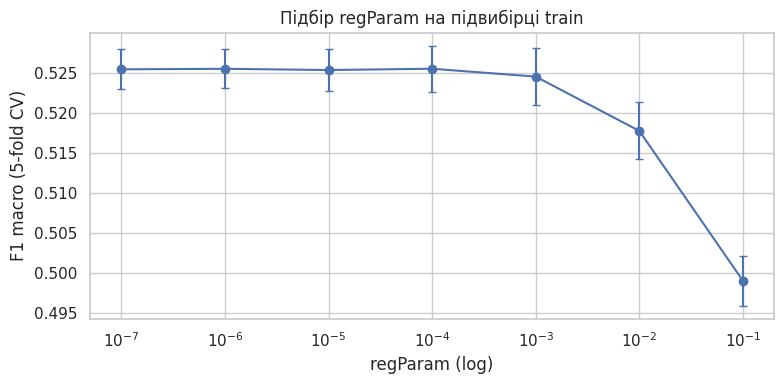

,regParam,F1 macro (CV),std
3,0.0001,0.5255,0.0029
1,0.0000,0.5255,0.0024
0,0.0000,0.5254,0.0025
2,0.0000,0.5253,0.0026
4,0.0010,0.5245,0.0035
5,0.0100,0.5177,0.0036
6,0.1000,0.4990,0.0031


In [5]:
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import Evaluator
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder


def confusion_matrix(pred):
    """Матриця помилок 4 × 4 (рядки — фактичний клас, стовпці — прогноз): рахує Spark, на драйвер — ≤ 16 чисел."""
    cm = np.zeros((len(LABELS), len(LABELS)), dtype=np.int64)
    for r in pred.groupBy(F.col("label").cast("int").alias("y"), F.col("prediction").cast("int").alias("p")).count().collect():
        cm[r["y"], r["p"]] = r["count"]
    return cm


def scores(cm):
    tp, actual, predicted = np.diag(cm), cm.sum(axis=1), cm.sum(axis=0)
    precision = np.divide(tp, predicted, out=np.zeros(len(tp)), where=predicted > 0)
    recall = np.divide(tp, actual, out=np.zeros(len(tp)), where=actual > 0)
    f1 = np.divide(2 * tp, actual + predicted, out=np.zeros(len(tp)), where=actual + predicted > 0)
    return {"accuracy": tp.sum() / cm.sum(), "balanced accuracy": recall.mean(),
            **{f"precision {c}": precision[i] for i, c in enumerate([1, 2, 3, 4])},
            **{f"recall {c}": recall[i] for i, c in enumerate([1, 2, 3, 4])},
            "F1 macro": f1.mean(), "F1 weighted": (f1 * actual).sum() / actual.sum()}


class MacroF1Evaluator(Evaluator):
    """F1 macro для CrossValidator (у MulticlassClassificationEvaluator «f1» — зважена)."""

    def _evaluate(self, dataset):
        return scores(confusion_matrix(dataset))["F1 macro"]

    def isLargerBetter(self):
        return True


BASE = LogisticRegression(family="multinomial", maxIter=200)
estimator = BASE.copy({BASE.weightCol: "weight"})
grid = ParamGridBuilder().addGrid(estimator.regParam, [1e-7, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1]).build()
t0 = time.time()
search = CrossValidator(estimator=estimator, estimatorParamMaps=grid, evaluator=MacroF1Evaluator(),
                        foldCol="fold", numFolds=5, parallelism=len(grid), seed=SEED).fit(tune)
cv_table = pd.DataFrame({"regParam": [m[estimator.regParam] for m in grid],
                         "F1 macro (CV)": search.avgMetrics, "std": search.stdMetrics})
best_params = {"regParam": float(cv_table.loc[cv_table["F1 macro (CV)"].idxmax(), "regParam"])}
print(f"Пошук: {time.time() - t0:.0f} c; найкращий F1 macro (CV) {cv_table['F1 macro (CV)'].max():.4f}, best_params = {best_params}")
tune.unpersist()

fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(cv_table["regParam"], cv_table["F1 macro (CV)"], yerr=cv_table["std"], fmt="o-", capsize=3)
ax.set(xscale="log", xlabel="regParam (log)", ylabel="F1 macro (5-fold CV)", title="Підбір regParam на підвибірці train")
plt.tight_layout()
plt.show()
cv_table.sort_values("F1 macro (CV)", ascending=False).round(4)

## Етап 3. Навчання та первинне оцінювання моделей

На повному train навчаємо 4 варіанти: **базові параметри** (значення Spark за замовчуванням: `regParam = 0` — без регуляризації; `maxIter = 200` замість 100 за замовчуванням — за 100 ітерацій L-BFGS модель не встигає зійтися) і **підібране** `regParam`, кожен **без зважування** і зі **збалансованими вагами класів** (`weightCol`, $w_c = N / (K\,n_c)$: кожен клас дає однаковий внесок у функцію втрат → модель частіше прогнозує рідкісні класи; аналог `class_weight="balanced"` у scikit-learn).

**Метрики** (усі рахує Spark: матриця помилок — `groupBy(label, prediction)`, ROC-AUC — `BinaryClassificationEvaluator` для кожного класу one-vs-rest):
* accuracy — для довідки: «завжди клас 2» вже дає ~78%;
* **balanced accuracy** — середній recall по класах;
* precision і recall кожного класу — особливо рідкісних класів 1 і 4;
* **F1 macro** (головна) і F1 weighted (зважений за кількістю записів класу);
* **ROC-AUC macro / weighted** (one-vs-rest; середнє AUC класів, просте і зважене за кількістю записів класу) — якість ранжування ймовірностей незалежно від порогу.

In [6]:
VARIANTS = {f"LogReg {kind}{' + balanced' if weighted else ''}":
            BASE.copy({BASE.regParam: best_params["regParam"] if kind == "tuned" else 0.0, **({BASE.weightCol: "weight"} if weighted else {})})
            for kind in ("base", "tuned") for weighted in (False, True)}

models, fit_info = {}, {}
for name, est in VARIANTS.items():
    t0 = time.time()
    models[name] = est.fit(train)
    fit_info[name] = {"regParam": est.getRegParam(), "секунд": round(time.time() - t0),
                      "ітерацій": models[name].summary.totalIterations}
    print(f"{name}: {fit_info[name]}")

LogReg base: {'regParam': 0.0, 'секунд': 341, 'ітерацій': 200}


LogReg base + balanced: {'regParam': 0.0, 'секунд': 356, 'ітерацій': 200}


LogReg tuned: {'regParam': 0.0001, 'секунд': 342, 'ітерацій': 200}


LogReg tuned + balanced: {'regParam': 0.0001, 'секунд': 282, 'ітерацій': 161}


In [7]:
from pyspark.ml.evaluation import BinaryClassificationEvaluator

PROBA = [f"p{k}" for k in LABELS]


def argmax(cols):
    """Номер стовпця з найбільшим значенням (за рівності — перший, як np.argmax)."""
    best = F.greatest(*cols)
    return F.coalesce(*[F.when(c == best, F.lit(float(k))) for k, c in enumerate(cols)])


def with_proba(model, df):
    """label, ймовірності класів p0…p3 окремими стовпцями і прогноз (argmax)."""
    return (model.transform(df).select("label", vector_to_array("probability").alias("_p"))
            .select("label", *[F.col("_p")[k].alias(c) for k, c in enumerate(PROBA)])
            .withColumn("prediction", argmax([F.col(c) for c in PROBA])))


def roc_auc(pred):
    """ROC-AUC кожного класу one-vs-rest: ймовірність класу — оцінка, «label == k» — бінарна ціль."""
    return np.array([BinaryClassificationEvaluator(rawPredictionCol=c, labelCol="_pos", metricName="areaUnderROC")
                     .evaluate(pred.withColumn("_pos", (F.col("label") == k).cast("double"))) for k, c in enumerate(PROBA)])


def metrics(pred):
    cached = pred.is_cached
    pred = pred.cache()
    cm, auc = confusion_matrix(pred), roc_auc(pred)
    if not cached:
        pred.unpersist()
    return {**scores(cm), "ROC-AUC macro": auc.mean(), "ROC-AUC weighted": (auc * cm.sum(axis=1)).sum() / cm.sum()}


def metrics_table(df):
    return pd.DataFrame({name: metrics(with_proba(m, df)) for name, m in models.items()}).T.rename_axis("модель")


results_train = metrics_table(train)
results_train.round(4)

,accuracy,balanced accuracy,precision 1,precision 2,precision 3,precision 4,recall 1,recall 2,recall 3,recall 4,F1 macro,F1 weighted,ROC-AUC macro,ROC-AUC weighted
модель,,,,,,,,,,,,,,
LogReg base,0.8913,0.5866,0.7270,0.9143,0.7960,0.6332,0.4521,0.9564,0.7279,0.2098,0.6420,0.8840,0.9433,0.9337
LogReg base + balanced,0.7447,0.8215,0.1869,0.9754,0.6498,0.1406,0.9577,0.7241,0.8183,0.7857,0.5267,0.7919,0.9343,0.9128
LogReg tuned,0.8913,0.5832,0.7385,0.9140,0.7962,0.6336,0.4399,0.9566,0.7272,0.2090,0.6401,0.8838,0.9432,0.9336
LogReg tuned + balanced,0.7446,0.8214,0.1858,0.9754,0.6500,0.1406,0.9580,0.7239,0.8181,0.7856,0.5263,0.7918,0.9342,0.9127


## Етап 4. Оцінювання на валідації та пороговий аналіз

Valid не бере участі в навчанні, тож на ньому порівнюємо варіанти, обираємо **лідера за F1 macro** і підбираємо для нього пороги рішення.

In [8]:
results_valid = metrics_table(valid)
LEADER = results_valid["F1 macro"].idxmax()
print(f"Лідер за F1 macro на valid: {LEADER} ({results_valid.loc[LEADER, 'F1 macro']:.4f})")
results_valid.round(4)

Лідер за F1 macro на valid: LogReg base (0.6475)


,accuracy,balanced accuracy,precision 1,precision 2,precision 3,precision 4,recall 1,recall 2,recall 3,recall 4,F1 macro,F1 weighted,ROC-AUC macro,ROC-AUC weighted
модель,,,,,,,,,,,,,,
LogReg base,0.8921,0.5933,0.7225,0.9157,0.7964,0.6282,0.4648,0.9558,0.7328,0.2197,0.6475,0.8852,0.9441,0.9347
LogReg base + balanced,0.7449,0.8219,0.1836,0.9757,0.6520,0.1405,0.9554,0.7236,0.8208,0.7876,0.5260,0.7922,0.9348,0.9132
LogReg tuned,0.8921,0.5900,0.7379,0.9153,0.7966,0.6291,0.4527,0.9560,0.7320,0.2192,0.6461,0.8850,0.9440,0.9346
LogReg tuned + balanced,0.7447,0.8218,0.1826,0.9757,0.6523,0.1405,0.9551,0.7235,0.8206,0.7880,0.5257,0.7921,0.9348,0.9132


**Порогова оптимізація.** Правило «клас з найбільшою ймовірністю» при сильному дисбалансі рідко обирає рідкісні класи (без зважування) або обирає їх надто часто (зі зважуванням). Мультикласовий поріг задаємо зсувами: $\hat y = \arg\max_k (\log p_k + b_k)$. Зсуви $b_k$ підбираємо на valid так, щоб максимізувати **F1 macro** (покоординатний пошук по сітці з 81 значення від −4 до 4, 3 проходи; зсув класу 2 фіксований, бо важливі лише різниці). Скориговані ймовірності — $\mathrm{softmax}(\log p + b)$: їхній argmax і є прогнозом, з них же будуємо ROC-криві.

**У Spark:** для одного класу всю сітку перевіряємо за один прохід — прогнози valid з'єднуються (`crossJoin`) з таблицею 81 значення зсуву, і `groupBy(зсув, label, prediction)` дає 81 матрицю помилок одразу; з них F1 macro кожного кандидата. Разом — 9 проходів по valid (3 класи × 3 проходи).

Підбір порогів обрано замість калібрування ймовірностей: калібрування робить ймовірності чесними, але правило argmax на каліброваних ймовірностях знову майже не обирає рідкісні класи, тож порогу все одно потрібен зсув.

Пороги підібрано на valid, тож метрики «з порогами» на valid трохи оптимістичні; чесна оцінка — на test (етап 5).

In [9]:
GRID = np.round(np.linspace(-4, 4, 81), 2)
GRID_DF = spark.createDataFrame([(i, float(g)) for i, g in enumerate(GRID)], ["i", "g"])


def log_p(k):
    return F.log(F.greatest(F.col(PROBA[k]), F.lit(1e-12)))


def shift(pred, offsets):
    """softmax(log p + b): скориговані ймовірності, argmax яких — прогноз з порогами."""
    z = [log_p(k) + float(b) for k, b in enumerate(offsets)]
    top = F.greatest(*z)
    e = [F.exp(zk - top) for zk in z]
    total = reduce(lambda a, b: a + b, e)
    return (pred.select("label", *[(ek / total).alias(c) for ek, c in zip(e, PROBA)])
            .withColumn("prediction", argmax([F.col(c) for c in PROBA])))


def tune_offsets(pred, ref=1, rounds=3):
    pred = pred.select("label", *PROBA).cache()
    offsets = np.zeros(len(LABELS))
    best = scores(confusion_matrix(shift(pred, offsets)))["F1 macro"]
    for _ in range(rounds):
        for k in LABELS:
            if k == ref:
                continue
            z = [log_p(j) + (F.col("g") if j == k else F.lit(float(offsets[j]))) for j in LABELS]
            counts = (pred.crossJoin(F.broadcast(GRID_DF)).withColumn("prediction", argmax(z))
                      .groupBy("i", F.col("label").cast("int").alias("y"), F.col("prediction").cast("int").alias("p")).count().collect())
            cms = np.zeros((len(GRID), len(LABELS), len(LABELS)), dtype=np.int64)
            for r in counts:
                cms[r["i"], r["y"], r["p"]] = r["count"]
            f1 = np.array([scores(cm)["F1 macro"] for cm in cms])
            if f1.max() > best:
                best, offsets[k] = f1.max(), GRID[f1.argmax()]
    pred.unpersist()
    return offsets


model = models[LEADER]
t0 = time.time()
OFFSETS = tune_offsets(with_proba(model, valid))
LEADER_NAME = f"{LEADER} + пороги"
print(f"Пороги підібрано за {time.time() - t0:.0f} c")


def leader_pred(df):
    return shift(with_proba(model, df), OFFSETS)


display(pd.Series(OFFSETS, index=CLASSES, name="зсув log-ймовірності").round(2).to_frame().T)
pd.DataFrame({LEADER: results_valid.loc[LEADER], LEADER_NAME: metrics(leader_pred(valid))}).T.rename_axis("valid").round(4)

Пороги підібрано за 45 c


,Severity 1,Severity 2,Severity 3,Severity 4
зсув log-ймовірності,0.5,0.0,0.4,1.2


,accuracy,balanced accuracy,precision 1,precision 2,precision 3,precision 4,recall 1,recall 2,recall 3,recall 4,F1 macro,F1 weighted,ROC-AUC macro,ROC-AUC weighted
valid,,,,,,,,,,,,,,
LogReg base,0.8921,0.5933,0.7225,0.9157,0.7964,0.6282,0.4648,0.9558,0.7328,0.2197,0.6475,0.8852,0.9441,0.9347
LogReg base + пороги,0.8868,0.6808,0.6348,0.9356,0.7599,0.4142,0.5953,0.9285,0.7879,0.4115,0.6832,0.8872,0.9437,0.9357


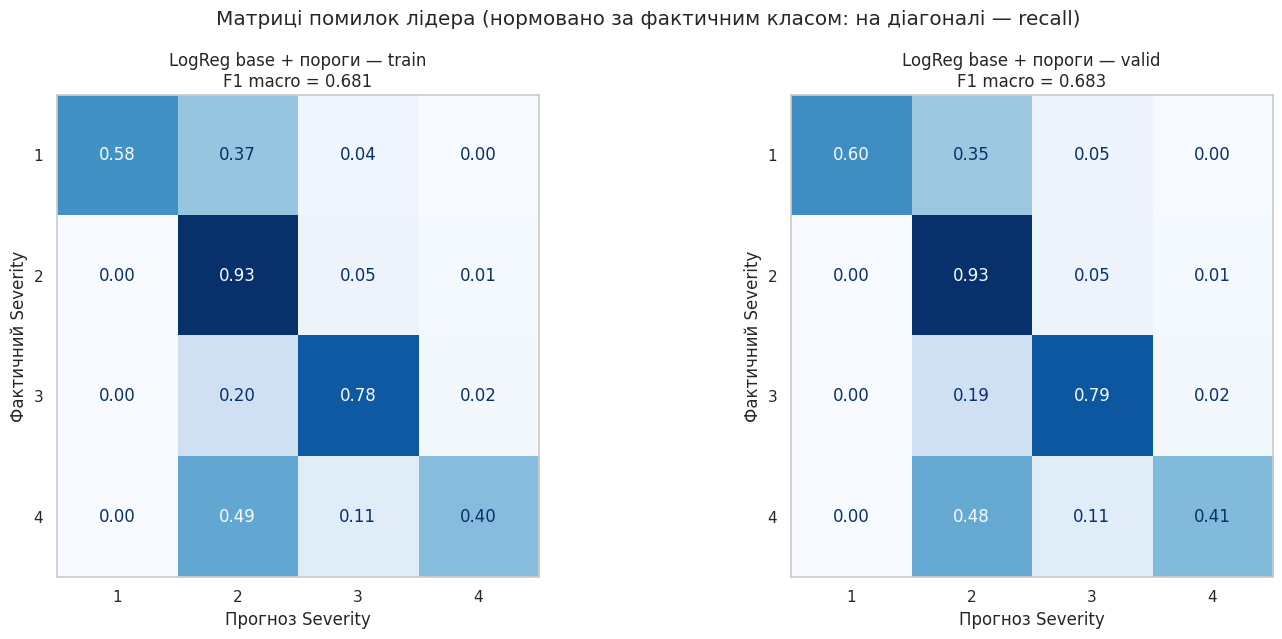

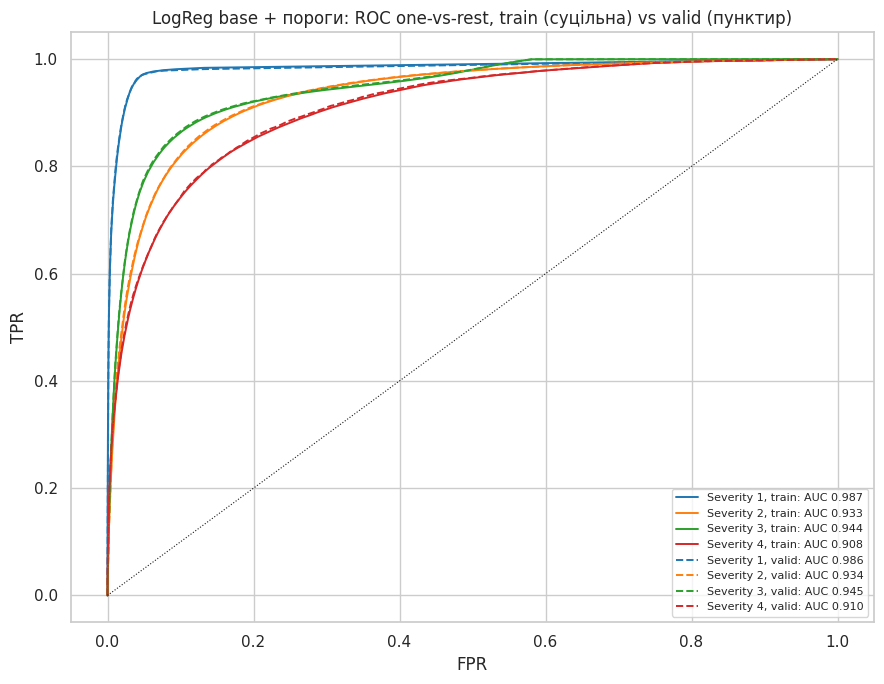

In [10]:
from sklearn.metrics import ConfusionMatrixDisplay


def roc_curve(pred, k, bins=1000):
    """ROC-крива класу k one-vs-rest: Spark рахує гістограму ймовірності (1000 бінів) окремо для позитивних і негативних."""
    h = (pred.groupBy(F.least(F.floor(F.col(PROBA[k]) * bins), F.lit(bins - 1)).alias("b"))
         .agg(F.sum((F.col("label") == k).cast("long")).alias("pos"), F.count("*").alias("n"))
         .orderBy(F.desc("b")).collect())
    pos = np.array([r["pos"] for r in h])
    neg = np.array([r["n"] - r["pos"] for r in h])
    return np.r_[0, np.cumsum(neg) / neg.sum()], np.r_[0, np.cumsum(pos) / pos.sum()]


def plot_confusion(ax, pred, title):
    cm = confusion_matrix(pred)
    ConfusionMatrixDisplay(cm / cm.sum(axis=1, keepdims=True), display_labels=[1, 2, 3, 4]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format=".2f")
    ax.grid(False)
    ax.set_title(f"{title}\nF1 macro = {scores(cm)['F1 macro']:.3f}")
    ax.set_xlabel("Прогноз Severity")
    ax.set_ylabel("Фактичний Severity")


def plot_roc(ax, curves, title):
    """curves: {мітка вибірки: (прогнози, стиль лінії)} — криві one-vs-rest кожного класу."""
    colors = sns.color_palette("tab10", 4)
    for split, (pred, ls) in curves.items():
        auc = roc_auc(pred)
        for k, cls in enumerate(CLASSES):
            fpr, tpr = roc_curve(pred, k)
            ax.plot(fpr, tpr, ls, color=colors[k], lw=1.4, label=f"{cls}, {split}: AUC {auc[k]:.3f}")
    ax.plot([0, 1], [0, 1], "k:", lw=0.8)
    ax.set(title=title, xlabel="FPR", ylabel="TPR")
    ax.legend(loc="lower right", fontsize=8)


pred_train_leader, pred_valid_leader = leader_pred(train).cache(), leader_pred(valid).cache()
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
plot_confusion(axes[0], pred_train_leader, f"{LEADER_NAME} — train")
plot_confusion(axes[1], pred_valid_leader, f"{LEADER_NAME} — valid")
fig.suptitle("Матриці помилок лідера (нормовано за фактичним класом: на діагоналі — recall)")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 7))
plot_roc(ax, {"train": (pred_train_leader, "-"), "valid": (pred_valid_leader, "--")},
         f"{LEADER_NAME}: ROC one-vs-rest, train (суцільна) vs valid (пунктир)")
plt.tight_layout()
plt.show()

## Етап 5. Фінальне оцінювання на тестовій вибірці

Test використовуємо один раз — для лідера з порогами, підібраними на valid. Це чесна оцінка якості на нових даних.

In [11]:
pred_test = leader_pred(test).cache()
results_test = pd.DataFrame({LEADER_NAME: metrics(pred_test)}).T.rename_axis("лідер (test)")
results_test.round(4)

,accuracy,balanced accuracy,precision 1,precision 2,precision 3,precision 4,recall 1,recall 2,recall 3,recall 4,F1 macro,F1 weighted,ROC-AUC macro,ROC-AUC weighted
лідер (test),,,,,,,,,,,,,,
LogReg base + пороги,0.887,0.6779,0.6341,0.9359,0.7585,0.4153,0.5823,0.9285,0.7885,0.4121,0.6816,0.8874,0.9431,0.9353


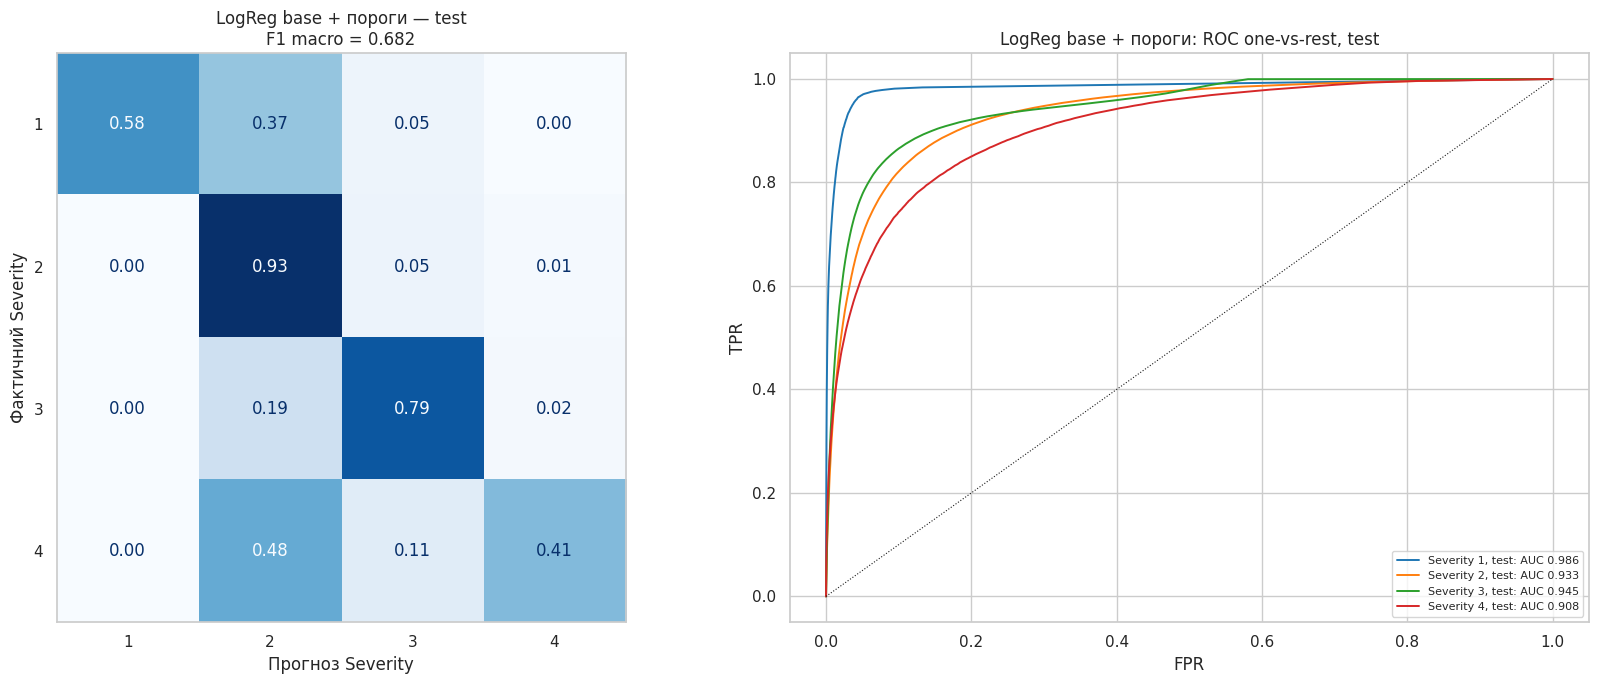

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(17, 7))
plot_confusion(axes[0], pred_test, f"{LEADER_NAME} — test")
plot_roc(axes[1], {"test": (pred_test, "-")}, f"{LEADER_NAME}: ROC one-vs-rest, test")
plt.tight_layout()
plt.show()

In [13]:
COLS_SUMMARY = ["accuracy", "balanced accuracy", "recall 1", "recall 4", "F1 macro", "F1 weighted", "ROC-AUC macro"]
summary = pd.DataFrame({"train (без порогів)": results_train.loc[LEADER, COLS_SUMMARY],
                        "valid (без порогів)": results_valid.loc[LEADER, COLS_SUMMARY],
                        "train (з порогами)": pd.Series(metrics(pred_train_leader))[COLS_SUMMARY],
                        "valid (з порогами)": pd.Series(metrics(pred_valid_leader))[COLS_SUMMARY],
                        "test (з порогами)": results_test.loc[LEADER_NAME, COLS_SUMMARY]}).T.round(4)
for df in (pred_train_leader, pred_valid_leader, pred_test):
    df.unpersist()
summary

,accuracy,balanced accuracy,recall 1,recall 4,F1 macro,F1 weighted,ROC-AUC macro
train (без порогів),0.8913,0.5866,0.4521,0.2098,0.6420,0.8840,0.9433
valid (без порогів),0.8921,0.5933,0.4648,0.2197,0.6475,0.8852,0.9441
train (з порогами),0.8863,0.6747,0.5844,0.4017,0.6806,0.8865,0.9430
valid (з порогами),0.8868,0.6808,0.5953,0.4115,0.6832,0.8872,0.9437
test (з порогами),0.8870,0.6779,0.5823,0.4121,0.6816,0.8874,0.9431


## Етап 6. SHAP-аналіз та інтерпретованість

**SHAP** розкладає прогноз на внески ознак: для кожного класу лог-шанс (margin, `rawPrediction` у Spark) = базове значення + сума внесків ознак. Пороги — зсув лог-шансів поверх моделі, тож на внески ознак вони не впливають. Для логістичної регресії з незалежними ознаками внесок ознаки $j$ у клас $k$ дорівнює рівно $\beta_{kj}\,(x_j - \bar x_j)$: `shap.LinearExplainer` отримує коефіцієнти Spark-моделі (`coefficientMatrix`, `interceptVector`), маскер `Independent` — середні з 2 000 записів train. На відміну від самих коефіцієнтів, SHAP враховує, як часто й наскільки ознака відхиляється від середнього.

**Вибірка:** ~5 000 записів test, **стратифікованих за класом** (`sampleBy`) — частки класів такі самі, як у test; рахувати SHAP на всіх 1.4 млн записів немає потреби. Обидві вибірки Spark відбирає й передає на драйвер як numpy-матриці — SHAP працює лише з ними. Сума внесків звіряється з `rawPrediction`, який рахує Spark.

* **Bar chart** — середній |SHAP| кожної ознаки, складений по класах (топ-20 стовпців матриці ознак);
* **Beeswarm** для кожного класу — кожна точка — запис, положення — внесок у лог-шанс класу, колір — значення ознаки;
* таблиця важливості **вихідних ознак** — внески one-hot категорій і бінів однієї ознаки додаються (`State`, `Distance(mi)` = значення + біни тощо).

/usr/local/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Фон: 2,000 записів train; записів за класами у вибірці SHAP: {'Severity 1': 40, 'Severity 2': 4035, 'Severity 3': 934, 'Severity 4': 129}


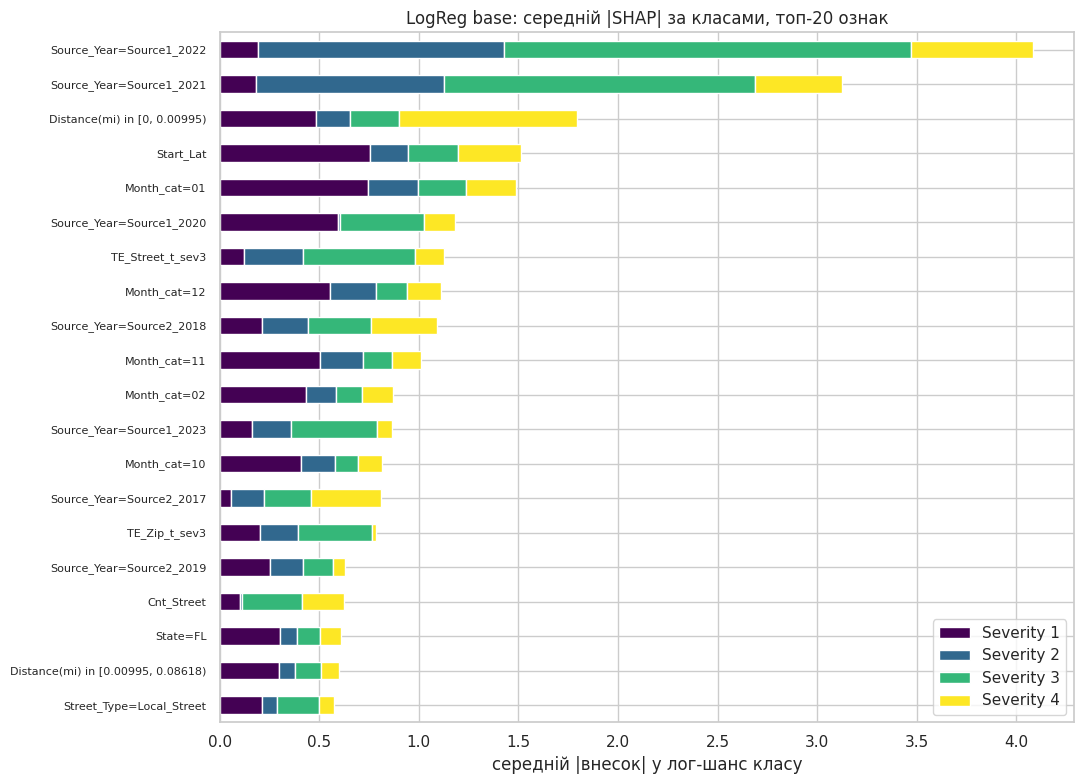

In [14]:
import shap

coef, intercept = model.coefficientMatrix.toArray(), model.interceptVector.toArray()
background = np.array([r["features"].toArray() for r in
                       train.sample(fraction=min(1.0, 3_000 / N["train"]), seed=SEED).limit(2_000).select("features").collect()])
explain_rows = (model.transform(test.sampleBy("label", {float(c): 5_000 / N["test"] for c in LABELS}, seed=SEED))
                .select("features", "label", "rawPrediction").collect())
X_explain = np.array([r["features"].toArray() for r in explain_rows])
y_explain = np.array([int(r["label"]) for r in explain_rows])
margin_spark = np.array([r["rawPrediction"].toArray() for r in explain_rows])
print(f"Фон: {len(background):,} записів train; записів за класами у вибірці SHAP:",
      dict(zip(CLASSES, np.bincount(y_explain, minlength=4).tolist())))

explainer = shap.LinearExplainer((coef, intercept), shap.maskers.Independent(background, max_samples=len(background)))
sv = explainer(X_explain)
sv.feature_names = FEATURES
assert np.allclose(sv.base_values + sv.values.sum(axis=1), margin_spark, atol=1e-4), "база + внески ≠ rawPrediction Spark"

imp = pd.DataFrame(np.abs(sv.values).mean(axis=0), index=FEATURES, columns=CLASSES)
fig, ax = plt.subplots(figsize=(11, 8))
imp.loc[imp.sum(axis=1).nlargest(20).index][::-1].plot.barh(stacked=True, ax=ax, colormap="viridis")
ax.set_title(f"{LEADER}: середній |SHAP| за класами, топ-20 ознак")
ax.set_xlabel("середній |внесок| у лог-шанс класу")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

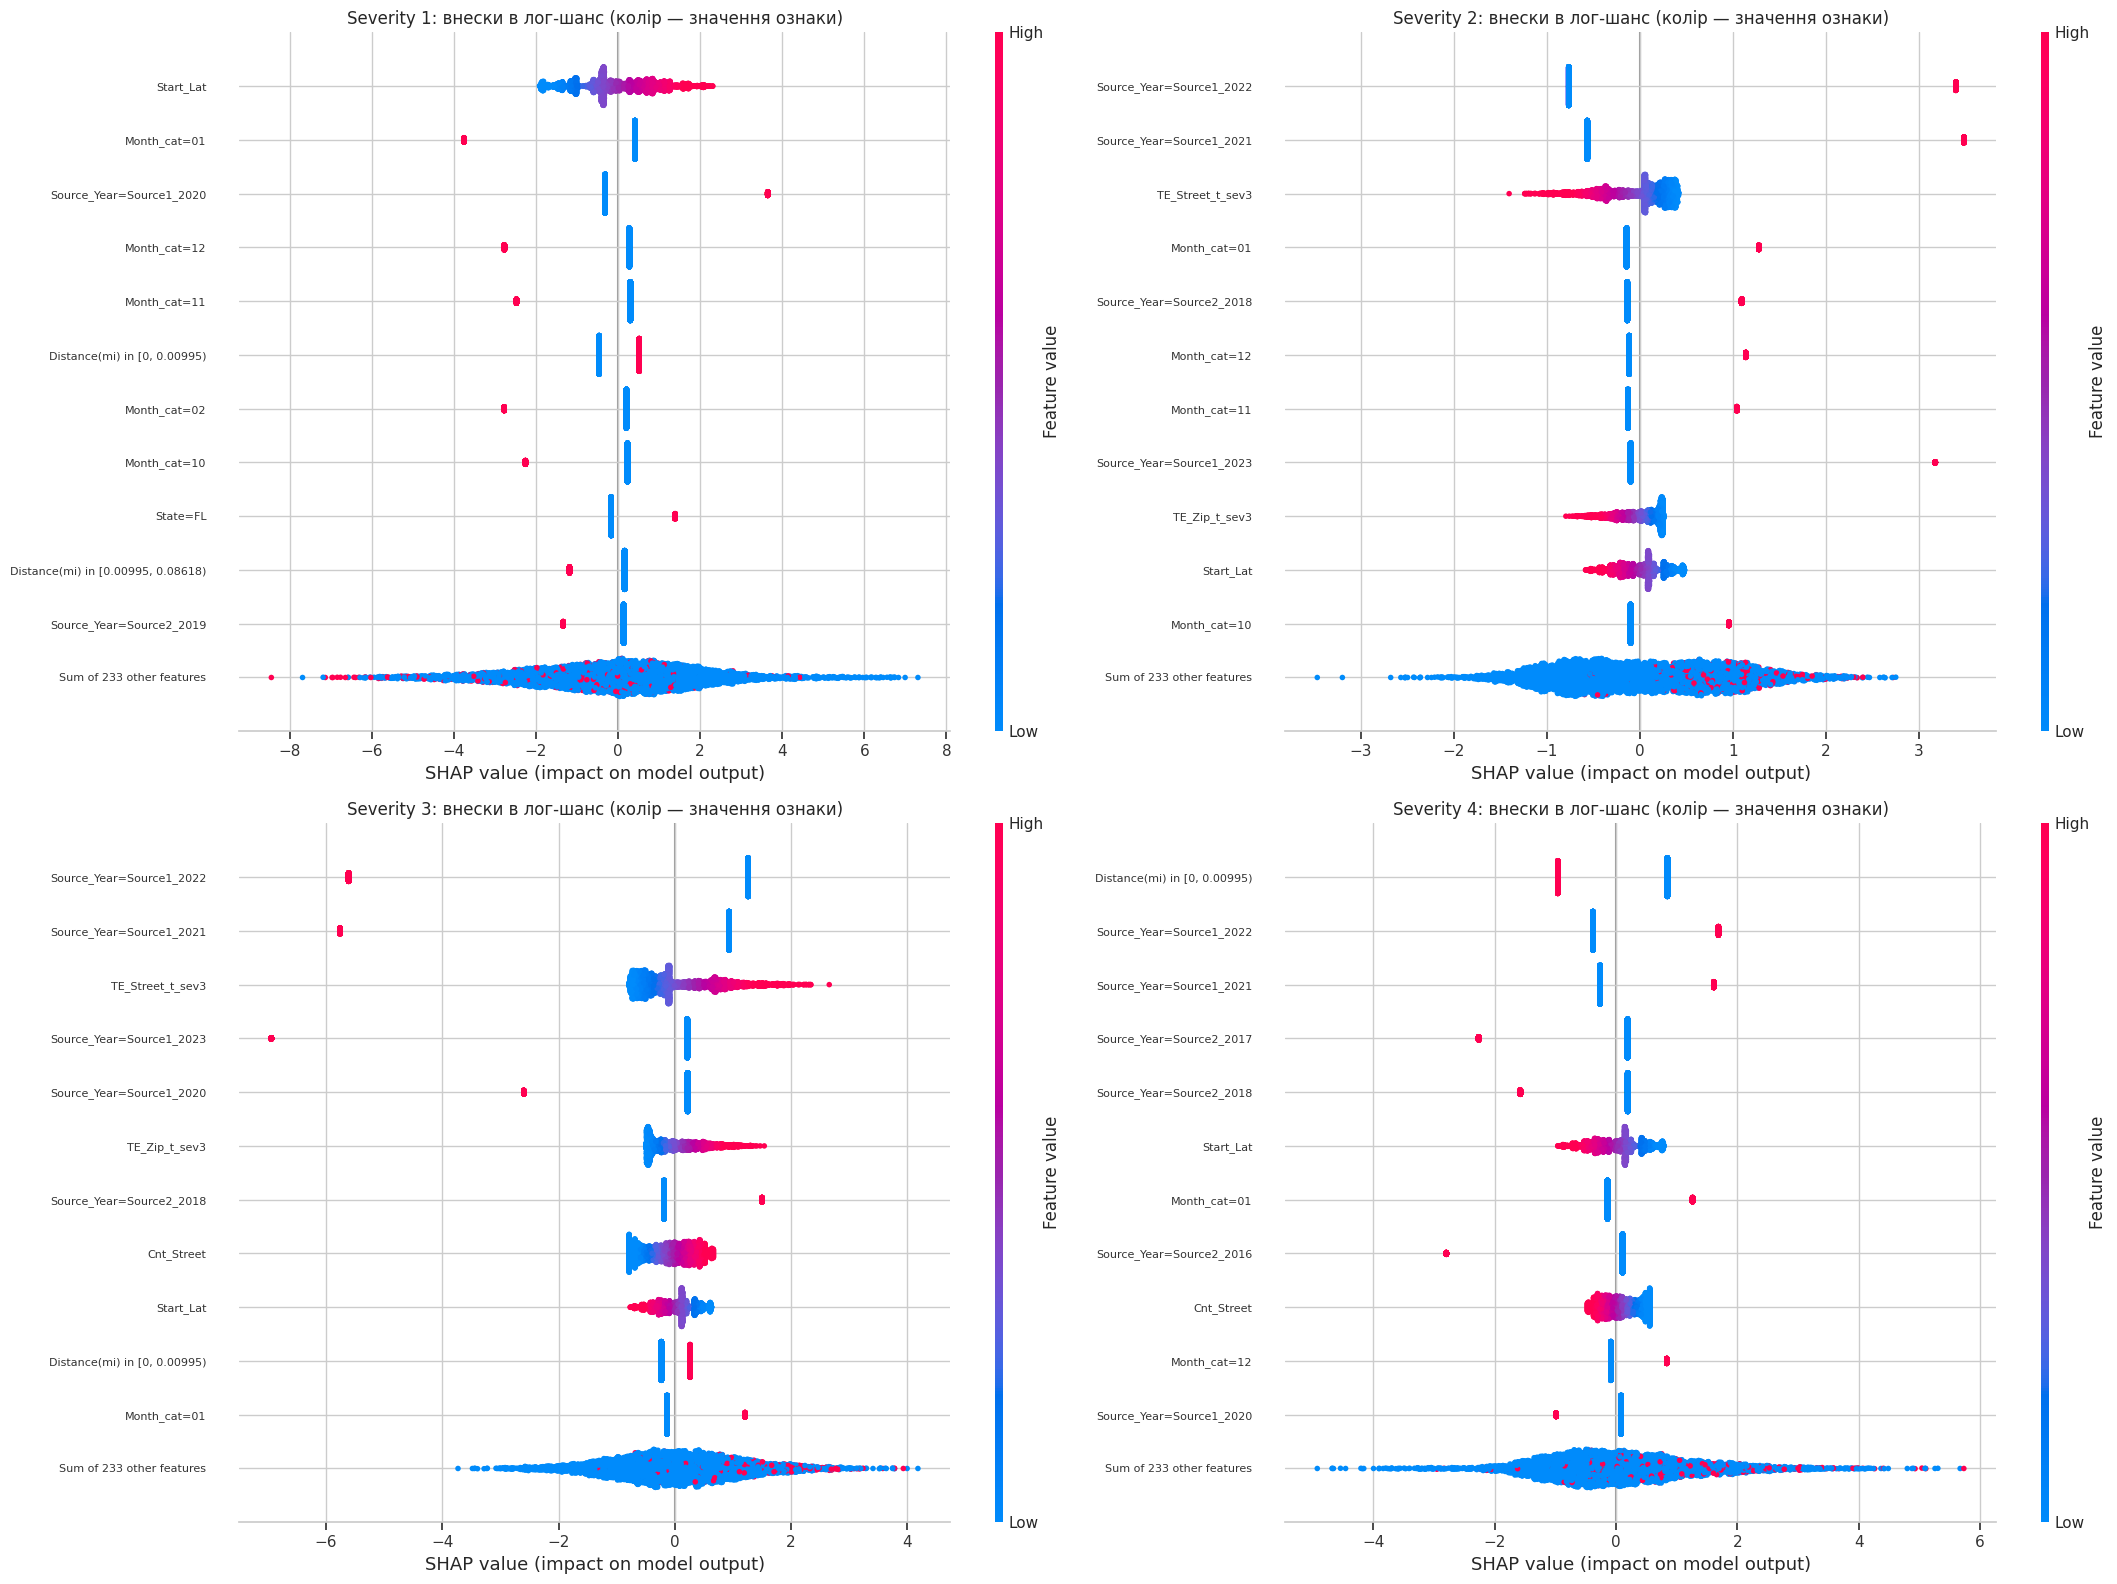

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(22, 16))
for k, ax in enumerate(axes.flat):
    shap.plots.beeswarm(sv[:, :, k], max_display=12, ax=ax, show=False, plot_size=None)
    ax.set_title(f"{CLASSES[k]}: внески в лог-шанс (колір — значення ознаки)")
    ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

In [16]:
def feature_group(name):
    if name.startswith("DoW_"):
        return "DayOfWeek"
    for sep in ("=", " in ["):
        if sep in name:
            return name.split(sep)[0]
    return name


GROUPS = [feature_group(f) for f in FEATURES]
grouped = pd.DataFrame({cls: pd.DataFrame(sv.values[:, :, k], columns=FEATURES).T.groupby(GROUPS).sum().T.abs().mean()
                        for k, cls in enumerate(CLASSES)})
grouped.assign(сума=grouped.sum(axis=1)).sort_values("сума", ascending=False).head(20).round(4)

,Severity 1,Severity 2,Severity 3,Severity 4,сума
Source_Year,1.4886,1.4264,3.3315,1.5593,7.8059
Month_cat,1.2954,0.5243,0.3896,0.3909,2.6002
Distance(mi),0.8557,0.2001,0.1773,1.1045,2.3375
State,0.7882,0.2494,0.3845,0.3917,1.8139
Start_Lat,0.7569,0.1910,0.2514,0.3145,1.5137
TE_Street_t_sev3,0.1235,0.2971,0.5622,0.1416,1.1244
HourType,0.3220,0.0764,0.2827,0.1963,0.8773
TE_Zip_t_sev3,0.2014,0.1911,0.3703,0.0223,0.7851
Timezone,0.1314,0.0708,0.2845,0.2530,0.7397
Cnt_Street,0.1007,0.0134,0.2991,0.2118,0.6251


## Збереження моделі

Spark-модель зберігається у власному форматі (`model.write()`, тека з метаданими й parquet коефіцієнтів) — її читає `LogisticRegressionModel.load`. Поруч — зсуви порогів і коефіцієнти у joblib, щоб прогнозувати без Spark.

In [17]:
from pyspark.ml.classification import LogisticRegressionModel

spark_path = MODELS_DIR / "classification_logreg_spark"
model.write().overwrite().save(str(spark_path))
assert np.allclose(LogisticRegressionModel.load(str(spark_path)).coefficientMatrix.toArray(), coef)

path = MODELS_DIR / "classification_logreg_spark.joblib"
joblib.dump({"variant": LEADER, "spark_model": spark_path.name, "coef": coef, "intercept": intercept, "log_offsets": OFFSETS,
             "params": {p.name: v for p, v in model.extractParamMap().items()}, "features": FEATURES,
             "classes": "label 0..3 = Severity 1..4",
             "predict": "argmax(log(softmax(X @ coef.T + intercept)) + log_offsets)"}, path)
print("Збережено:", spark_path.name, "і", path.name)
spark.stop()

Збережено: classification_logreg_spark і classification_logreg_spark.joblib


## Висновки

| Варіант (valid) | F1 macro | Balanced acc. | Recall 1 / 4 | Precision 1 / 4 |
|---|---|---|---|---|
| LogReg base (`regParam = 0`) | 0.648 | 0.593 | 0.46 / 0.22 | 0.72 / 0.63 |
| LogReg base + balanced | 0.526 | **0.822** | **0.96 / 0.79** | 0.18 / 0.14 |
| LogReg tuned (`regParam = 10⁻⁴`) | 0.646 | 0.590 | 0.45 / 0.22 | 0.74 / 0.63 |
| LogReg tuned + balanced | 0.526 | 0.822 | 0.96 / 0.79 | 0.18 / 0.14 |
| **LogReg base + пороги з valid** | **0.683** | 0.681 | 0.60 / 0.41 | 0.63 / 0.41 |

**Фінальна оцінка на test (LogReg base + пороги):** accuracy **0.887**, balanced accuracy **0.678**, **F1 macro 0.682**, F1 weighted 0.887, ROC-AUC macro **0.943** / weighted 0.935. F1 по класах: 0.61 / 0.93 / 0.77 / 0.41.

* **Підбір `regParam` майже нічого не змінює:** на підвибірці F1 macro (CV) однаковий для $\lambda$ від 10⁻⁷ до 10⁻⁴ (0.5253–0.5255), сильніша регуляризація лише шкодить ($\lambda$ = 0.1: 0.499). На повному train підібране $\lambda$ = 10⁻⁴ навіть трохи гірше за модель без регуляризації (F1 macro на valid 0.646 проти 0.648), тож лідер — базовий варіант. При ~4.8 млн записів і 244 ознаках регуляризація практично не впливає на коефіцієнти — це очікувано для лінійної моделі на великих даних.
* **Зважування класів (`weightCol`)** знаходить 96% ДТП класу 1 і 79% — класу 4 (balanced accuracy 0.82), але ціною частих хибних тривог (precision 0.18 і 0.14), тож за F1 macro воно найгірше (0.53). Такий варіант доречний, якщо пропустити тяжку ДТП дорожче, ніж перевірити зайву.
* **Пороги, підібрані на valid, дають найкращий баланс:** F1 macro 0.648 → 0.683 переважно за рахунок рідкісних класів (recall класу 4: 0.22 → 0.41, класу 1: 0.46 → 0.60). ROC-AUC при цьому не змінюється (0.944) — пороги змінюють робочу точку, а не ранжування.
* **Перенавчання немає:** F1 macro з порогами на train / valid / test — 0.681 / 0.683 / 0.682, ROC-AUC macro — 0.943 / 0.944 / 0.943. Test підтверджує оцінку з valid, тож оптимізм від підбору порогів на valid мінімальний.
* **Найслабше місце — клас 4** (F1 0.41): тяжкі ДТП часто плутаються з класом 2. У Source1 класи 2 і 4 відрізняються фактичним впливом на рух (перекриттям), якого серед ознак на момент ДТП немає — це межа для будь-якої моделі на цих ознаках.
* **Spark на великих даних:** кожен варіант навчається на 4.8 млн записів за ~5–6 хв (L-BFGS, ~1.3 с на ітерацію, розподілено по всіх ядрах); три з чотирьох варіантів дійшли до ліміту `maxIter = 200`, але метрики збігаються з попередньою версією на scikit-learn (`lbfgs`, `max_iter=300`): F1 macro на test 0.682 в обох, тож додаткові ітерації якості помітно не змінять. Увесь ноутбук у Docker — ~40 хв.
* **SHAP:** найсильніша ознака — `Source_Year` (сумарний середній |SHAP| 7.8 — утричі більше за наступну): джерело й рік визначають схему розмітки тяжкості. Далі — `Month_cat`, `Distance(mi)` (головна ознака для класів 4 і 1: довга ділянка впливу → тяжча ДТП), `State`, `Start_Lat`, історична тяжкість ДТП на вулиці / індексі (`TE_Street_t_sev3`, `TE_Zip_t_sev3`), `HourType`, `Timezone`.

**Нові дані: невідомий рік джерела** (перевірка виконувалась на попередній версії даних — 235 ознак, модель scikit-learn). `Source_Year` — найсильніша ознака, і вона прив'язана до років train. Перевірка «на майбутньому» (модель навчена **без 2023 р.**, оцінка на 42 167 test-записах `Source1_2023`):

| Сценарій | Accuracy | F1 класу 4 | % прогнозів класу 3 |
|---|---|---|---|
| рік був у навчанні (поточна модель) | 0.969 | 0.324 | 0% |
| невідомий рік → референсна категорія (усі `Source_Year` = 0) | 0.744 | 0.366 | 21% |
| **невідомий рік → останній рік того ж джерела** | **0.969** | 0.311 | 0% |

Тому правило для нових даних: **невідомий `Source_Year` замінюється на останній відомий рік того ж джерела** (`Source1_2023`, `Source2_2022`, `Source3_2022`; див. `metadata.json` → `unseen_source_year`). Воно працює, лише поки джерело не змінює схему розмітки (Source1 змінив її у 2021 р. — класи 1 і 3 зникли), тож на нових даних потрібні моніторинг розподілу прогнозів і періодичне перенавчання.

**Що могло б покращити якість:** нелінійні моделі (градієнтний бустинг, наприклад `GBTClassifier` у Spark — для мультикласу через `OneVsRest`), які враховують взаємодії ознак — наприклад, різну схему розмітки тяжкості в різних джерелах і роках.

Модель збережено: `data/models/classification_logreg_spark/` (`LogisticRegressionModel.load`) і `data/models/classification_logreg_spark.joblib` (коефіцієнти + зсуви порогів; прогноз — `argmax(log p + log_offsets)`).